<a href="https://colab.research.google.com/github/Kazato-ce/Computer-Vision/blob/main/B%C3%A0iT%E1%BA%ADp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Thông tin sinh viên

*   MSSV: 24521338
*   Họ và tên: Nguyễn Đoàn Thanh Phong


# I.Chuẩn bị
## 1.Kết nối Google Drive

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Khai báo thư viện và đường dẫn

In [31]:
import os, glob, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product

from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report


DATA_DIR = "/content/drive/MyDrive/Thị Giác Máy Tính/HoaVietNam2027"
train_folder = os.path.join(DATA_DIR, "train")
test_folder  = os.path.join(DATA_DIR, "test")

## 3. Đọc dữ liệu
Hàm đọc ảnh, đồng thời lưu **đường dẫn file** để Yêu cầu 3 có thể in danh sách tên ảnh.

Kiểm tra tồn tại file chưa

In [32]:
print(os.listdir(DATA_DIR))                         # phải thấy 'train' và 'test'
print(os.listdir(os.path.join(DATA_DIR, "train")))  # phải thấy tên các loài hoa

['train', 'test']
['Sen', 'Lan', 'Ga', 'Mai', 'Hong', 'Cuc', 'Dao', 'Tho']


In [33]:
def load_dataset(folder):
    images, labels, paths = [], [], []
    class_names = sorted(d for d in os.listdir(folder)
                         if os.path.isdir(os.path.join(folder, d)))
    for label, cname in enumerate(class_names):
        for p in sorted(glob.glob(os.path.join(folder, cname, "*.*"))):
            img = cv2.imread(p)
            if img is None:
                continue
            images.append(img); labels.append(label); paths.append(p)
    return images, np.array(labels), paths, class_names

train_images, y_train, train_paths, class_names = load_dataset(train_folder)
test_images,  y_test,  test_paths,  class_names_test = load_dataset(test_folder)
assert class_names == class_names_test

print("Các lớp:", class_names)
print("Số ảnh train:", len(train_images), "| Số ảnh test:", len(test_images))
print("Train mỗi lớp:", dict(zip(class_names, np.bincount(y_train))))
print("Test mỗi lớp :", dict(zip(class_names, np.bincount(y_test))))

Các lớp: ['Cuc', 'Dao', 'Ga', 'Hong', 'Lan', 'Mai', 'Sen', 'Tho']
Số ảnh train: 285 | Số ảnh test: 92
Train mỗi lớp: {'Cuc': np.int64(40), 'Dao': np.int64(35), 'Ga': np.int64(40), 'Hong': np.int64(35), 'Lan': np.int64(35), 'Mai': np.int64(30), 'Sen': np.int64(40), 'Tho': np.int64(30)}
Test mỗi lớp : {'Cuc': np.int64(10), 'Dao': np.int64(12), 'Ga': np.int64(15), 'Hong': np.int64(15), 'Lan': np.int64(10), 'Mai': np.int64(10), 'Sen': np.int64(10), 'Tho': np.int64(10)}


Kiểm Tra

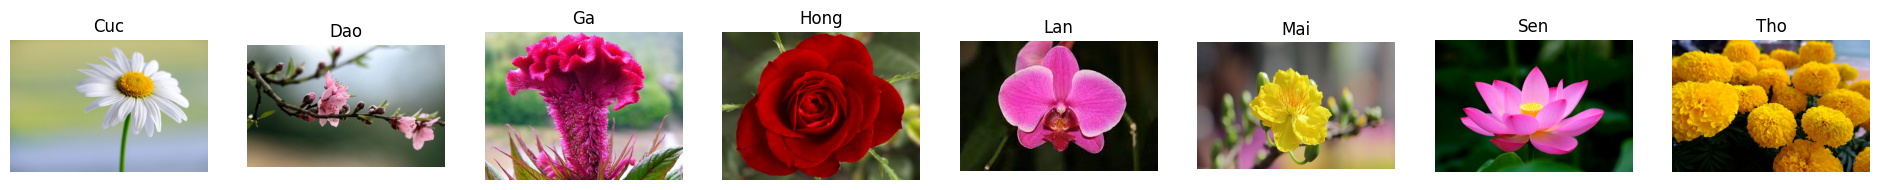

In [34]:
plt.figure(figsize=(3 * len(class_names), 3))
for c, name in enumerate(class_names):
    idx = np.where(y_train == c)[0][0]
    plt.subplot(1, len(class_names), c + 1)
    plt.imshow(cv2.cvtColor(train_images[idx], cv2.COLOR_BGR2RGB))
    plt.title(name); plt.axis("off")
plt.show()

# II.Các yêu cầu của bài

# 1. Xác định đặc trưng X (từ Bài tập 1)
Đề: *X là đặc trưng có độ chính xác cao nhất trong Bài tập 1*. Phần này chạy lại quy trình Bài 1 trên bộ dữ liệu này
(KNN tìm tham số tối ưu trên histogram RGB, sau đó so sánh 4 đặc trưng) để **tự chọn X**.
Nếu bạn đã biết X từ bài 1 của mình, đặt `FEATURE_X_OVERRIDE` thành một trong:
`"Histogram RGB 256"`, `"Histogram HSV 8x8x8"`, `"Moment màu"`, `"Màu chủ đạo"`.

In [35]:
def hist_rgb(img_bgr, bins=256):
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    feats = []
    for ch in range(3):
        h = cv2.calcHist([rgb], [ch], None, [bins], [0, 256]).flatten()
        feats.append(h / h.sum())
    return np.concatenate(feats)

def hist_hsv(img_bgr, bins=8):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0, 1, 2], None, [bins]*3, [0, 180, 0, 256, 0, 256]).flatten()
    return h / h.sum()

def color_moments(img_bgr):
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).reshape(-1, 3).astype(np.float64)
    mean, std = rgb.mean(axis=0), rgb.std(axis=0)
    skew = np.cbrt(np.mean((rgb - mean) ** 3, axis=0))
    return np.concatenate([mean, std, skew])

def dominant_colors(img_bgr, k=3):
    small = cv2.resize(img_bgr, (64, 64), interpolation=cv2.INTER_AREA)
    px = cv2.cvtColor(small, cv2.COLOR_BGR2RGB).reshape(-1, 3).astype(np.float64)
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(px)
    order = np.argsort(-np.bincount(km.labels_, minlength=k))   # sắp theo độ phổ biến
    return km.cluster_centers_[order].flatten()

feature_fns = {
    "Histogram RGB 256":   hist_rgb,
    "Histogram HSV 8x8x8": lambda im: hist_hsv(im, 8),
    "Moment màu":          color_moments,
    "Màu chủ đạo":         dominant_colors,
}
features = {}   # name -> (X_train, X_test)
for name, fn in feature_fns.items():
    features[name] = (np.array([fn(im) for im in train_images]),
                      np.array([fn(im) for im in test_images]))
    print(f"{name:<22s} -> {features[name][0].shape[1]} chiều")

Histogram RGB 256      -> 768 chiều
Histogram HSV 8x8x8    -> 512 chiều
Moment màu             -> 9 chiều
Màu chủ đạo            -> 9 chiều


# Quy trình Bài 1: KNN grid search trên histogram RGB -> tham số tối ưu

In [36]:
Xtr, Xte = features["Histogram RGB 256"]
best_acc, knn_params = -1, None
for k, w, m in product(range(1, 11), ['uniform', 'distance'],
                       ['braycurtis', 'canberra', 'correlation', 'cosine', 'euclidean', 'minkowski']):
    acc = accuracy_score(y_test, KNeighborsClassifier(n_neighbors=k, weights=w, metric=m).fit(Xtr, y_train).predict(Xte))
    if acc > best_acc:               # giữ bộ đầu tiên đạt điểm cao nhất
        best_acc, knn_params = acc, {"n_neighbors": k, "weights": w, "metric": m}
print("Tham số KNN tối ưu (Bài 1):", knn_params, f"| accuracy = {best_acc:.4f}\n")

Tham số KNN tối ưu (Bài 1): {'n_neighbors': 3, 'weights': 'distance', 'metric': 'braycurtis'} | accuracy = 0.5652



# So sánh 4 đặc trưng với cùng tham số

In [37]:
acc_by_feature = {}
for name, (Xtr, Xte) in features.items():
    pred = KNeighborsClassifier(**knn_params).fit(Xtr, y_train).predict(Xte)
    acc_by_feature[name] = accuracy_score(y_test, pred)
acc_table = pd.Series(acc_by_feature, name="Accuracy (KNN)").sort_values(ascending=False)
display(acc_table.round(4).to_frame())

,Accuracy (KNN)
Histogram HSV 8x8x8,0.6739
Histogram RGB 256,0.5652
Moment màu,0.4457
Màu chủ đạo,0.4457


##Check kết quả

In [38]:
FEATURE_X_OVERRIDE = None

FEATURE_X = FEATURE_X_OVERRIDE or acc_table.idxmax()
X_train, X_test = features[FEATURE_X]
print("Đặc trưng X được chọn:", FEATURE_X, "| số chiều:", X_train.shape[1])

Đặc trưng X được chọn: Histogram HSV 8x8x8 | số chiều: 512


# Yêu cầu 1: LogisticRegression + GridSearchCV (tối ưu macro-F1)
Tham số cần tìm: `penalty` ∈ {l1, l2, elasticnet, None} và `solver` ∈ {lbfgs, liblinear, newton-cg, newton-cholesky, sag, saga}.

Lưu ý:
* **Không phải cặp nào cũng hợp lệ** (ví dụ `lbfgs` không hỗ trợ `l1`; chỉ `saga` hỗ trợ `elasticnet`). Vì vậy `param_grid` được viết thành *danh sách các lưới con* theo từng solver, chỉ gồm các cặp hợp lệ. Với `elasticnet` phải kèm `l1_ratio`.
* Một số solver có thể không hỗ trợ phân loại đa lớp ở một số phiên bản scikit-learn (ví dụ `liblinear`, `newton-cholesky`). Đặt `error_score=np.nan` để các tổ hợp lỗi bị bỏ qua thay vì làm dừng cả chương trình; bảng kết quả bên dưới sẽ cho biết tổ hợp nào lỗi.
* Dùng `StandardScaler` trong Pipeline: hồi quy logistic nhạy với thang đo, và scaler chỉ được fit trên từng fold train (không rò rỉ dữ liệu).
* Chọn tham số bằng **cross-validation 5 fold trên tập train**, tập test chỉ dùng để đánh giá cuối.

In [39]:
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

param_grid_lr = [
    {"clf__solver": ["lbfgs"],           "clf__penalty": ["l2", None]},
    {"clf__solver": ["liblinear"],       "clf__penalty": ["l1", "l2"]},
    {"clf__solver": ["newton-cg"],       "clf__penalty": ["l2", None]},
    {"clf__solver": ["newton-cholesky"], "clf__penalty": ["l2", None]},
    {"clf__solver": ["sag"],             "clf__penalty": ["l2", None]},
    {"clf__solver": ["saga"],            "clf__penalty": ["l1", "l2", None]},
    {"clf__solver": ["saga"],            "clf__penalty": ["elasticnet"], "clf__l1_ratio": [0.5]},
]

## số fold không được vượt quá số ảnh train của lớp ít nhất

In [29]:
n_splits = int(min(5, np.bincount(y_train).min()))
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

gs_lr = GridSearchCV(pipe_lr, param_grid_lr, scoring="f1_macro", cv=cv,
                     n_jobs=-1, refit=True, error_score=np.nan)
gs_lr.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('clf',
                                        LogisticRegression(max_iter=1000,
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid=[{'clf__penalty': ['l2', None],
                          'clf__solver': ['lbfgs']},
                         {'clf__penalty': ['l1', 'l2'],
                          'clf__solver': ['liblinear']},
                         {'clf__penalty': ['l2', None],
                          'clf__solver': ['newton-cg']},
                         {'clf__penalty': ['l2', None],
                          'clf__solver': ['newton-cholesky']},
                         {'clf__penalty': ['l2', None], 'clf__solver': ['sag']},
                         {'clf__penalty': ['l1', 'l2', None],
                          'clf__solver': ['saga']},
                         {'clf__l1_ratio': [0.5],
                          'clf__penalty': ['elasticnet'],
                          'clf__solver': ['saga']}],
             scoring='f1_macro')

In [40]:
def cv_table(gs):
    t = pd.DataFrame(gs.cv_results_)
    cols = [c for c in t.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
    t = t[cols].rename(columns=lambda c: c.replace("param_clf__", ""))
    t["penalty"] = t["penalty"].apply(lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else v)
    t["trạng thái"] = np.where(t["mean_test_score"].isna(), "lỗi/không hỗ trợ", "ok")
    return t.sort_values("rank_test_score").reset_index(drop=True)

display(cv_table(gs_lr).round(4))
print("\nTHAM SỐ TỐI ƯU (LogisticRegression):", gs_lr.best_params_)
print(f"Macro-F1 trung bình CV ({n_splits} fold) cao nhất: {gs_lr.best_score_:.4f}")

,penalty,solver,l1_ratio,mean_test_score,std_test_score,rank_test_score,trạng thái
0,l2,saga,NaN,0.6220,0.0656,1,ok
1,l2,sag,NaN,0.6193,0.0548,2,ok
2,None,saga,NaN,0.6159,0.0602,3,ok
3,None,lbfgs,NaN,0.6102,0.0541,4,ok
4,None,newton-cholesky,NaN,0.6102,0.0541,4,ok
5,l2,lbfgs,NaN,0.6086,0.0570,6,ok
6,None,sag,NaN,0.6037,0.0562,7,ok
7,l2,newton-cg,NaN,0.6000,0.0489,8,ok
8,l2,newton-cholesky,NaN,0.6000,0.0489,8,ok
9,elasticnet,saga,0.5,0.5995,0.0430,10,ok



THAM SỐ TỐI ƯU (LogisticRegression): {'clf__penalty': 'l2', 'clf__solver': 'saga'}
Macro-F1 trung bình CV (5 fold) cao nhất: 0.6220


# Yêu cầu 2: Kết quả phân loại bằng `classification_report`
## 2.1. LogisticRegression (mô hình tốt nhất từ Yêu cầu 1) trên tập test

In [41]:
y_pred_lr = gs_lr.best_estimator_.predict(X_test)
print(classification_report(y_test, y_pred_lr, target_names=class_names, zero_division=0))
acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr  = f1_score(y_test, y_pred_lr, average="macro")
print(f"Accuracy = {acc_lr:.4f} | Macro-F1 = {f1_lr:.4f}")

              precision    recall  f1-score   support

         Cuc       0.64      0.70      0.67        10
         Dao       0.88      0.58      0.70        12
          Ga       0.62      0.87      0.72        15
        Hong       0.50      0.47      0.48        15
         Lan       0.67      0.40      0.50        10
         Mai       0.57      0.80      0.67        10
         Sen       0.44      0.40      0.42        10
         Tho       0.89      0.80      0.84        10

    accuracy                           0.63        92
   macro avg       0.65      0.63      0.63        92
weighted avg       0.65      0.63      0.62        92

Accuracy = 0.6304 | Macro-F1 = 0.6252


## 2.2. SGDClassifier (làm tương tự Yêu cầu 1)
`SGDClassifier` không có tham số `solver` (luôn dùng SGD), nên lưới tham số gồm: `loss`, `penalty` ∈ {l1, l2, elasticnet, None} và `alpha`
(hệ số điều chuẩn; ảnh hưởng mạnh tới kết quả). `elasticnet` kèm `l1_ratio`. Vẫn chọn theo **macro-F1** bằng cross-validation trên tập train.

In [42]:
pipe_sgd = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)),
])

param_grid_sgd = [
    {"clf__loss": ["hinge", "log_loss", "modified_huber"],
     "clf__penalty": ["l1", "l2", None],
     "clf__alpha": [1e-5, 1e-4, 1e-3, 1e-2]},
    {"clf__loss": ["hinge", "log_loss", "modified_huber"],
     "clf__penalty": ["elasticnet"],
     "clf__alpha": [1e-5, 1e-4, 1e-3, 1e-2],
     "clf__l1_ratio": [0.15, 0.5, 0.85]},
]

gs_sgd = GridSearchCV(pipe_sgd, param_grid_sgd, scoring="f1_macro", cv=cv,
                      n_jobs=-1, refit=True, error_score=np.nan)
gs_sgd.fit(X_train, y_train)

display(cv_table(gs_sgd).head(10).round(4))
print("\nTHAM SỐ TỐI ƯU (SGDClassifier):", gs_sgd.best_params_)
print(f"Macro-F1 trung bình CV cao nhất: {gs_sgd.best_score_:.4f}")

,alpha,loss,penalty,l1_ratio,mean_test_score,std_test_score,rank_test_score,trạng thái
0,0.010,hinge,elasticnet,0.15,0.6416,0.0773,1,ok
1,0.010,modified_huber,elasticnet,0.15,0.6394,0.0866,2,ok
2,0.001,log_loss,l2,NaN,0.6379,0.0595,3,ok
3,0.010,hinge,l2,NaN,0.6361,0.0744,4,ok
4,0.010,log_loss,elasticnet,0.15,0.6335,0.0869,5,ok
5,0.010,log_loss,l2,NaN,0.6317,0.0809,6,ok
6,0.001,log_loss,elasticnet,0.15,0.6291,0.0529,7,ok
7,0.010,modified_huber,l2,NaN,0.6289,0.0702,8,ok
8,0.001,modified_huber,l2,NaN,0.6280,0.0739,9,ok
9,0.010,log_loss,elasticnet,0.50,0.6279,0.0697,10,ok



THAM SỐ TỐI ƯU (SGDClassifier): {'clf__alpha': 0.01, 'clf__l1_ratio': 0.15, 'clf__loss': 'hinge', 'clf__penalty': 'elasticnet'}
Macro-F1 trung bình CV cao nhất: 0.6416


In [43]:
y_pred_sgd = gs_sgd.best_estimator_.predict(X_test)
print(classification_report(y_test, y_pred_sgd, target_names=class_names, zero_division=0))
acc_sgd = accuracy_score(y_test, y_pred_sgd)
f1_sgd  = f1_score(y_test, y_pred_sgd, average="macro")
print(f"Accuracy = {acc_sgd:.4f} | Macro-F1 = {f1_sgd:.4f}")

              precision    recall  f1-score   support

         Cuc       0.55      0.60      0.57        10
         Dao       0.89      0.67      0.76        12
          Ga       0.72      0.87      0.79        15
        Hong       0.47      0.47      0.47        15
         Lan       0.71      0.50      0.59        10
         Mai       0.69      0.90      0.78        10
         Sen       0.40      0.40      0.40        10
         Tho       0.89      0.80      0.84        10

    accuracy                           0.65        92
   macro avg       0.66      0.65      0.65        92
weighted avg       0.66      0.65      0.65        92

Accuracy = 0.6522 | Macro-F1 = 0.6501


## 2.3. So sánh tổng hợp

Đặc trưng X: Histogram HSV 8x8x8


,Mô hình,Accuracy (test),Macro-F1 (test)
0,KNN (Bài 1),0.6739,0.6739
1,LogisticRegression,0.6304,0.6252
2,SGDClassifier,0.6522,0.6501


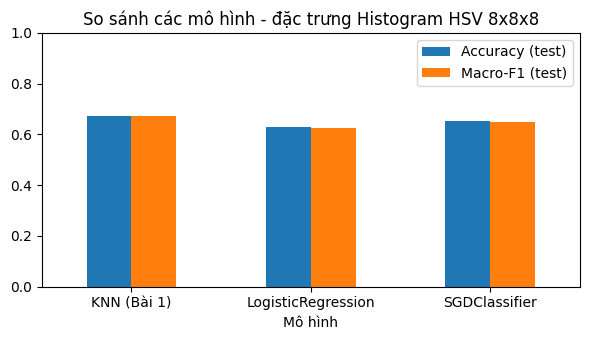

In [44]:
summary = pd.DataFrame({
    "Mô hình": ["KNN (Bài 1)", "LogisticRegression", "SGDClassifier"],
    "Accuracy (test)": [acc_by_feature[FEATURE_X], acc_lr, acc_sgd],
    "Macro-F1 (test)": [
        f1_score(y_test, KNeighborsClassifier(**knn_params).fit(*[features[FEATURE_X][0], y_train]).predict(X_test), average="macro"),
        f1_lr, f1_sgd],
})
print("Đặc trưng X:", FEATURE_X)
display(summary.round(4))

summary.set_index("Mô hình").plot.bar(figsize=(6, 3.5), ylim=(0, 1), rot=0)
plt.title(f"So sánh các mô hình - đặc trưng {FEATURE_X}")
plt.tight_layout(); plt.show()

# Nhận xét

* **Đặc trưng X:** Histogram HSV 8×8×8 (accuracy Bài 1 = 0.6739), cao hơn RGB (0.5652), Moment màu và Màu chủ đạo (0.4457).
* **LogisticRegression:** tối ưu là `penalty = l2`, `solver = saga`, macro-F1 CV = 0.6220; trên test accuracy = 0.6304, macro-F1 = 0.6252. Các solver dùng `l2` cho điểm gần nhau; `liblinear` thấp nhất (do huấn luyện kiểu one-vs-rest).
* **SGDClassifier:** tối ưu là `loss = hinge`, `penalty = elasticnet`, `l1_ratio = 0.15`, `alpha = 0.01`, macro-F1 CV = 0.6416; trên test accuracy = 0.6522, macro-F1 = 0.6501, nhỉnh hơn LogisticRegression.
* **So sánh với KNN:** KNN (0.6739) nhỉnh hơn SGD (0.6522) và LogisticRegression (0.6304), nên mô hình tuyến tính không tốt hơn KNN trên bộ dữ liệu này.
* **Lớp kém:** Hồng (F1 ≈ 0.47) và Sen (F1 ≈ 0.41) thấp nhất, có thể do cùng tông màu hồng nên histogram màu dễ nhầm; Vạn thọ cao nhất (0.84) nhờ màu vàng cam đặc trưng.